In [13]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import TypedDict, Literal
from dotenv import load_dotenv
from langchain_groq import ChatGroq
import os


In [19]:
model= ChatGroq(model="openai/gpt-oss-120b", temperature=0.2 , api_key=os.getenv("GROQ_API_KEY"))

In [20]:
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative"]= Field(description="sentiment of the review")

In [45]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description="The category of the issue is given")
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description="The emotional tone express by the user")
    urgency: Literal["low", "medium", "high"] = Field(description="How urgent or critical the issue appears to be")


In [46]:
structure_model= model.with_structured_output(SentimentSchema)
diagnosis_model= model.with_structured_output(DiagnosisSchema)

In [24]:
prompt="what is the sentiment of the following review - the soft toy is  good"
structure_output= structure_model.invoke(prompt).sentiment
print(structure_output)

positive


In [39]:
class ReviewState(TypedDict):
    review:str
    sentiment:Literal["positive", "negative"]
    diagnosis: dict
    response:str

In [40]:
def find_sentiment(state:ReviewState):
    prompt=f" what is the  sentiment of the following review-{state['review']}"
    sentiment=structure_model.invoke(prompt).sentiment
    return {"sentiment": sentiment}

In [41]:
def condition_review(state: ReviewState)->Literal["positive_response","diagnosis_response"]:
    if state['sentiment']=="positive":
        return "positive_response"
    else:
        return "diagnosis_response"

In [51]:
def positive_response(state:ReviewState):
    prompt=f"""give the thank you overwelming message for visiting the website-{state["review"]}"""
    response=model.invoke(prompt)
    return {"response":response}

In [ ]:
def diagnosis_response(state:ReviewState):
    prompt=f""" diagnosis the negative review {state["review"]}\n
    return issue_type, tone, urgency."""
    response=diagnosis_model.invoke(prompt)
    return{"diagnosis": response.model_dump()}

In [54]:
def negative_response(state:ReviewState):
    diagnosis= state['diagnosis']
    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency '{diagnosis["urgency"]}
Write an empathetic, helpful resolution message.
"""

    response = model.invoke(prompt).content
    
    return {'response': response}

In [56]:
graph= StateGraph(ReviewState)
graph.add_node("find_sentiment",find_sentiment)
graph.add_node("positive_response",positive_response)
graph.add_node("diagnosis_response",diagnosis_response)
graph.add_node("negative_response",negative_response)

graph.add_edge(START, "find_sentiment")
graph.add_conditional_edges("find_sentiment",condition_review)
graph.add_edge("positive_response",END)
graph.add_edge("diagnosis_response","negative_response")
graph.add_edge("negative_response",END)

workflow= graph.compile()


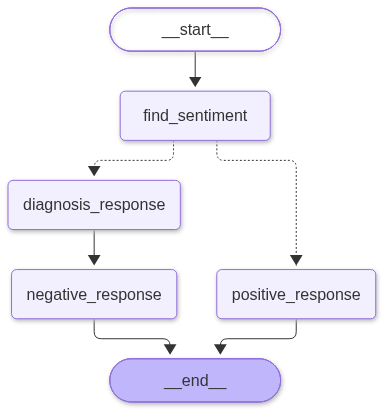

In [57]:
workflow

In [59]:
initial_state={'review': "the soft toy is  not good"}
final_state=workflow.invoke(initial_state)
print(final_state)


{'review': 'the soft toy is  not good', 'sentiment': 'negative', 'diagnosis': {'issue_type': 'Bug', 'tone': 'disappointed', 'urgency': 'medium'}, 'response': 'Hi there,\n\nI’m really sorry to hear that you’ve run into this bug – I completely understand how frustrating that can be, especially when you’re counting on things to work smoothly. Let’s get this sorted out together.\n\n### Quick troubleshooting steps\n1. **Refresh & Restart**  \n   - Close the app/website completely (make sure it’s not running in the background).  \n   - Clear your browser cache or, if you’re on a mobile app, clear the app’s cache in your device settings.  \n   - Re‑open the service and see if the issue persists.\n\n2. **Check for Updates**  \n   - Make sure you’re using the latest version of the app or that your browser is up‑to‑date.  \n   - If an update is available, install it and try again.\n\n3. **Reproduce the bug**  \n   - Try to perform the same steps that led to the problem.  \n   - Note any error me